# AWGN and BER Performance in a Multipath OFDM Channel

## Objective

This notebook extends the noiseless multipath OFDM model developed previously by introducing additive white Gaussian noise (AWGN).

The goals are to:

1. Build a reproducible QPSK/OFDM transmitter using a 64-point IFFT and a 16-sample cyclic prefix.
2. Pass the transmitted waveform through the same frequency-selective multipath channel used previously.
3. Add complex AWGN at controlled signal-to-noise ratio (SNR) values.
4. Perform cyclic-prefix removal and FFT processing at the receiver.
5. Apply zero-forcing frequency-domain equalization using perfect knowledge of the channel response.
6. Measure the bit error rate (BER) before and after equalization over a range of SNR values.
7. Examine how noise and weak channel subcarriers affect received QPSK symbols.

For this experiment, SNR is defined using the average power of the clean received sample stream relative to the average complex-noise power. It is therefore treated as a sample-domain SNR rather than being labeled directly as $E_b/N_0$.

This experiment provides the next step from the noiseless multipath baseline toward a more realistic wireless communication model.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Separate random-number generators keep the transmitted data
# and added noise independently reproducible.
data_rng = np.random.default_rng(42)
noise_rng = np.random.default_rng(12345)

# OFDM parameters
N_fft = 64
N_cp = 16

# QPSK carries two bits per complex symbol
bits_per_qpsk_symbol = 2

# Use enough bits to obtain meaningful BER measurements.
# 131072 bits = 1024 complete 64-subcarrier OFDM symbols.
num_bits = 131_072

bits_per_ofdm_symbol = bits_per_qpsk_symbol * N_fft

assert num_bits % bits_per_ofdm_symbol == 0

print("FFT size:", N_fft)
print("Cyclic-prefix length:", N_cp)
print("Bits per QPSK symbol:", bits_per_qpsk_symbol)
print("Bits per OFDM symbol:", bits_per_ofdm_symbol)
print("Total transmitted bits:", num_bits)
print("Expected OFDM symbols:", num_bits // bits_per_ofdm_symbol)

FFT size: 64
Cyclic-prefix length: 16
Bits per QPSK symbol: 2
Bits per OFDM symbol: 128
Total transmitted bits: 131072
Expected OFDM symbols: 1024


## QPSK/OFDM Transmitter

A reproducible binary sequence is first mapped to normalized QPSK symbols.

The Gray-coded mapping used throughout this project is

$$
00 \rightarrow \frac{1+j}{\sqrt{2}},
$$

$$
01 \rightarrow \frac{1-j}{\sqrt{2}},
$$

$$
11 \rightarrow \frac{-1-j}{\sqrt{2}},
$$

$$
10 \rightarrow \frac{-1+j}{\sqrt{2}}.
$$

Each QPSK symbol therefore has unit energy.

The QPSK symbols are arranged into blocks of 64 frequency-domain subcarriers. A 64-point inverse fast Fourier transform (IFFT) converts each block to the time domain.

A 16-sample cyclic prefix is then formed by copying the final 16 samples of each useful OFDM symbol and placing them at its beginning. Each transmitted OFDM block therefore contains

$$
64 + 16 = 80
$$

time-domain samples.

In [2]:
# Generate reproducible binary data
bits = data_rng.integers(
    low=0,
    high=2,
    size=num_bits
)

# Group the bits into pairs for QPSK modulation
bit_pairs = bits.reshape(-1, 2)

# Gray-coded normalized QPSK mapping
I = 1 - 2 * bit_pairs[:, 0]
Q = 1 - 2 * bit_pairs[:, 1]

qpsk_symbols = (I + 1j * Q) / np.sqrt(2)

# Arrange QPSK symbols into 64-subcarrier OFDM blocks
ofdm_frequency_symbols = qpsk_symbols.reshape(-1, N_fft)

# Convert each frequency-domain OFDM block to the time domain
ofdm_time_symbols = np.fft.ifft(
    ofdm_frequency_symbols,
    axis=1
)

# Add the cyclic prefix
cyclic_prefix = ofdm_time_symbols[:, -N_cp:]

ofdm_with_cp = np.concatenate(
    (cyclic_prefix, ofdm_time_symbols),
    axis=1
)

# Serialize all OFDM blocks into one transmitted waveform
tx_serial = ofdm_with_cp.reshape(-1)

num_qpsk_symbols = len(qpsk_symbols)
num_ofdm_symbols = ofdm_frequency_symbols.shape[0]
block_length = N_fft + N_cp

print("Number of transmitted bits:", len(bits))
print("Number of QPSK symbols:", num_qpsk_symbols)
print("Number of OFDM symbols:", num_ofdm_symbols)
print("Useful OFDM symbol length:", N_fft)
print("Cyclic-prefix length:", N_cp)
print("Transmitted OFDM block length:", block_length)
print("Total transmitted samples:", len(tx_serial))
print(
    "Average QPSK symbol energy:",
    f"{np.mean(np.abs(qpsk_symbols) ** 2):.6f}"
)

# Sanity checks
assert num_qpsk_symbols == num_bits // 2
assert ofdm_frequency_symbols.shape == (1024, 64)
assert ofdm_time_symbols.shape == (1024, 64)
assert ofdm_with_cp.shape == (1024, 80)
assert len(tx_serial) == 81_920
assert np.allclose(
    np.mean(np.abs(qpsk_symbols) ** 2),
    1.0
)

Number of transmitted bits: 131072
Number of QPSK symbols: 65536
Number of OFDM symbols: 1024
Useful OFDM symbol length: 64
Cyclic-prefix length: 16
Transmitted OFDM block length: 80
Total transmitted samples: 81920
Average QPSK symbol energy: 1.000000


## Multipath Channel and Clean Received Reference

The OFDM waveform is next passed through the same frequency-selective multipath channel used in the previous experiment.

The discrete-time channel impulse response contains three propagation paths:

- a direct path at delay 0,
- a reflected path at delay 3 samples,
- a weaker reflected path at delay 8 samples.

Before normalization, the complex path coefficients are

$$
h[0] = 1,
$$

$$
h[3] = 0.45e^{j0.6},
$$

and

$$
h[8] = 0.25e^{-j0.9}.
$$

The channel is normalized to unit total energy,

$$
\sum_{\ell}|h[\ell]|^2 = 1.
$$

Because the maximum channel delay is 8 samples while the cyclic prefix contains 16 samples,

$$
N_{\mathrm{CP}} \geq L_h - 1,
$$

so the cyclic prefix is sufficiently long for this channel.

The transmitted serial OFDM waveform is convolved with the channel impulse response to produce a clean received reference signal. No additive noise is introduced yet. This clean signal will later be used both to validate the receiver and to define the sample-domain SNR used when AWGN is added.

In [3]:
# Three-path complex baseband multipath channel
h = np.zeros(9, dtype=complex)

h[0] = 1.0
h[3] = 0.45 * np.exp(1j * 0.6)
h[8] = 0.25 * np.exp(-1j * 0.9)

# Normalize the channel to unit total energy
h = h / np.sqrt(np.sum(np.abs(h) ** 2))

channel_energy = np.sum(np.abs(h) ** 2)
max_channel_delay = len(h) - 1

# Frequency response at the 64 OFDM subcarriers
H = np.fft.fft(h, n=N_fft)

print("Channel impulse-response length:", len(h))
print("Maximum channel delay:", max_channel_delay, "samples")
print("Cyclic-prefix length:", N_cp, "samples")
print("Normalized channel energy:", channel_energy)
print("Minimum subcarrier magnitude:", f"{np.min(np.abs(H)):.4f}")
print("Maximum subcarrier magnitude:", f"{np.max(np.abs(H)):.4f}")

# The cyclic prefix must cover the maximum channel delay
assert N_cp >= max_channel_delay

# Channel normalization check
assert np.allclose(channel_energy, 1.0)

Channel impulse-response length: 9
Maximum channel delay: 8 samples
Cyclic-prefix length: 16 samples
Normalized channel energy: 0.9999999999999996
Minimum subcarrier magnitude: 0.3156
Maximum subcarrier magnitude: 1.5078


In [4]:
# Pass the serialized OFDM waveform through the multipath channel
clean_rx_full = np.convolve(
    tx_serial,
    h,
    mode="full"
)

# Retain the samples corresponding to the transmitted OFDM stream.
# The remaining samples are only the final channel tail.
clean_rx_serial = clean_rx_full[:len(tx_serial)]

# Average received sample power.
# This quantity will be used to define the AWGN level later.
clean_rx_power = np.mean(np.abs(clean_rx_serial) ** 2)

print("Transmitted sample count:", len(tx_serial))
print("Full convolution sample count:", len(clean_rx_full))
print("Retained clean received samples:", len(clean_rx_serial))
print("Average clean received sample power:", f"{clean_rx_power:.8f}")

assert len(clean_rx_serial) == len(tx_serial)
assert clean_rx_power > 0

Transmitted sample count: 81920
Full convolution sample count: 81928
Retained clean received samples: 81920
Average clean received sample power: 0.01564021


## Noiseless Receiver Validation

Before adding noise, the clean multipath received signal is processed through the OFDM receiver.

The serial received waveform is divided back into 80-sample OFDM blocks. The first 16 samples of each block are removed as the cyclic prefix, leaving the 64 useful samples.

A 64-point fast Fourier transform (FFT) then converts each received OFDM symbol back to the frequency domain.

With a sufficiently long cyclic prefix and no additive noise, each received subcarrier should satisfy

$$
Y[k] = H[k]X[k],
$$

where

- $X[k]$ is the transmitted QPSK subcarrier symbol,
- $H[k]$ is the channel frequency response, and
- $Y[k]$ is the received subcarrier symbol.

Verifying this relationship establishes a clean reference before AWGN is introduced.

In [5]:
# Reshape the clean received serial stream into OFDM blocks
clean_rx_blocks = clean_rx_serial.reshape(
    num_ofdm_symbols,
    block_length
)

# Remove the cyclic prefix
clean_rx_without_cp = clean_rx_blocks[:, N_cp:]

# Transform the useful samples back to the frequency domain
clean_rx_frequency = np.fft.fft(
    clean_rx_without_cp,
    axis=1
)

# Theoretical noiseless frequency-domain result
expected_clean_rx_frequency = (
    ofdm_frequency_symbols * H[np.newaxis, :]
)

# Measure numerical agreement
clean_channel_model_error = np.max(
    np.abs(
        clean_rx_frequency
        - expected_clean_rx_frequency
    )
)

print("Received block-array shape:", clean_rx_blocks.shape)
print("Shape after CP removal:", clean_rx_without_cp.shape)
print("Frequency-domain shape:", clean_rx_frequency.shape)
print(
    "Maximum clean-channel model error:",
    f"{clean_channel_model_error:.3e}"
)

assert clean_rx_blocks.shape == (1024, 80)
assert clean_rx_without_cp.shape == (1024, 64)
assert clean_rx_frequency.shape == (1024, 64)

assert np.allclose(
    clean_rx_frequency,
    expected_clean_rx_frequency,
    atol=1e-12
)

Received block-array shape: (1024, 80)
Shape after CP removal: (1024, 64)
Frequency-domain shape: (1024, 64)
Maximum clean-channel model error: 1.024e-15


## Complex AWGN Model

The clean multipath signal is now corrupted by additive white Gaussian noise (AWGN).

For a target sample-domain signal-to-noise ratio,

$$
\mathrm{SNR}
=
\frac{P_s}{P_n},
$$

where $P_s$ is the average power of the clean received complex baseband samples and $P_n$ is the average complex noise power.

In decibels,

$$
\mathrm{SNR}_{\mathrm{dB}}
=
10\log_{10}
\left(
\frac{P_s}{P_n}
\right).
$$

Therefore, for a selected SNR,

$$
P_n
=
\frac{P_s}
{10^{\mathrm{SNR}_{\mathrm{dB}}/10}}.
$$

Complex AWGN is generated as

$$
n[m]
=
\sqrt{\frac{P_n}{2}}
\left(
n_I[m] + jn_Q[m]
\right),
$$

where $n_I[m]$ and $n_Q[m]$ are independent zero-mean, unit-variance Gaussian random variables.

The factor of $1/2$ ensures that

$$
E\{|n[m]|^2\}=P_n.
$$

Noise is added to the received time-domain waveform before cyclic-prefix removal and FFT processing, representing additive receiver noise in the complex baseband signal.

In [6]:
# Add complex AWGN for a requested sample-domain SNR
def add_complex_awgn(signal, snr_db, rng):
    signal_power = np.mean(np.abs(signal) ** 2)

    snr_linear = 10 ** (snr_db / 10)
    noise_power = signal_power / snr_linear

    noise = np.sqrt(noise_power / 2) * (
        rng.standard_normal(signal.shape)
        + 1j * rng.standard_normal(signal.shape)
    )

    noisy_signal = signal + noise

    return noisy_signal, noise, noise_power

### AWGN Sanity Check

Before performing a full BER sweep, one SNR value is tested to verify that the generated complex noise has the intended power.

A target sample-domain SNR of 10 dB is used. Because the noise sequence is finite, its measured power and measured SNR will not be exactly equal to their theoretical values, but they should be very close.

In [7]:
# Use a separate reproducible RNG for the noise experiments
noise_rng = np.random.default_rng(2026)

test_snr_db = 10.0

noisy_rx_serial, test_noise, target_noise_power = add_complex_awgn(
    clean_rx_serial,
    test_snr_db,
    noise_rng
)

measured_noise_power = np.mean(np.abs(test_noise) ** 2)

measured_snr_db = 10 * np.log10(
    clean_rx_power / measured_noise_power
)

print("Target SNR:", f"{test_snr_db:.2f} dB")
print("Clean received signal power:", f"{clean_rx_power:.8f}")
print("Target noise power:", f"{target_noise_power:.8f}")
print("Measured noise power:", f"{measured_noise_power:.8f}")
print("Measured SNR:", f"{measured_snr_db:.3f} dB")

assert len(noisy_rx_serial) == len(clean_rx_serial)
assert np.isclose(
    measured_snr_db,
    test_snr_db,
    atol=0.15
)

Target SNR: 10.00 dB
Clean received signal power: 0.01564021
Target noise power: 0.00156402
Measured noise power: 0.00156176
Measured SNR: 10.006 dB


## Noisy OFDM Receiver with Zero-Forcing Equalization

The noisy time-domain waveform is processed using the same receiver structure as before:

$$
\text{received samples}
\rightarrow
\text{CP removal}
\rightarrow
\text{FFT}
\rightarrow
\text{frequency-domain equalization}
\rightarrow
\text{QPSK demodulation}.
$$

After the FFT, the received subcarrier is

$$
Y[k]
=
H[k]X[k] + W[k],
$$

where $W[k]$ represents the transformed AWGN.

With perfect knowledge of the channel, zero-forcing equalization gives

$$
\hat{X}[k]
=
\frac{Y[k]}{H[k]}.
$$

Unlike the noiseless experiment, equalization cannot remove the additive noise. In addition, weak subcarriers can amplify noise through the factor $1/H[k]$.

In [8]:
def receive_equalize_and_demodulate(rx_serial):
    # Reconstruct transmitted OFDM blocks
    rx_blocks = rx_serial.reshape(
        num_ofdm_symbols,
        block_length
    )

    # Remove cyclic prefix
    rx_without_cp = rx_blocks[:, N_cp:]

    # FFT back to the frequency domain
    rx_frequency = np.fft.fft(
        rx_without_cp,
        axis=1
    )

    # Perfect-channel zero-forcing equalization
    equalized_frequency = (
        rx_frequency / H[np.newaxis, :]
    )

    # Flatten back into the QPSK-symbol sequence
    equalized_symbols = equalized_frequency.reshape(-1)

    # Hard-decision QPSK demodulation
    recovered_first_bits = (
        equalized_symbols.real < 0
    ).astype(int)

    recovered_second_bits = (
        equalized_symbols.imag < 0
    ).astype(int)

    recovered_bit_pairs = np.column_stack(
        (
            recovered_first_bits,
            recovered_second_bits
        )
    )

    recovered_bits = recovered_bit_pairs.reshape(-1)

    return equalized_symbols, recovered_bits

In [9]:
test_equalized_symbols, test_recovered_bits = (
    receive_equalize_and_demodulate(
        noisy_rx_serial
    )
)

test_bit_errors = np.count_nonzero(
    bits != test_recovered_bits
)

test_ber = test_bit_errors / len(bits)

print("Test SNR:", f"{test_snr_db:.2f} dB")
print("Transmitted bits:", len(bits))
print("Recovered bits:", len(test_recovered_bits))
print("Bit errors:", test_bit_errors)
print("BER:", f"{test_ber:.6e}")

assert len(test_recovered_bits) == len(bits)

Test SNR: 10.00 dB
Transmitted bits: 131072
Recovered bits: 131072
Bit errors: 2089
BER: 1.593781e-02


## BER Performance Versus SNR

The single-SNR test verified that the AWGN generator and noisy OFDM receiver operate correctly. The experiment is now repeated over a range of sample-domain SNR values.

At each SNR, several independent AWGN realizations are generated. The recovered bits from all trials are compared with the transmitted bit sequence, and the resulting errors are accumulated to estimate the bit error rate.

Because the channel response is frequency selective, different OFDM subcarriers experience different channel magnitudes. After zero-forcing equalization,

$$
\hat{X}[k]
=
X[k]
+
\frac{W[k]}{H[k]}.
$$

Consequently, subcarriers for which $|H[k]|$ is small experience greater post-equalization noise enhancement.

For the FFT convention used by NumPy, complex time-domain noise with power $P_n$ produces frequency-domain noise power $N_{\mathrm{FFT}}P_n$ on each subcarrier. For normalized QPSK, the theoretical bit-error probability on subcarrier $k$ is therefore

$$
P_b[k]
=
Q\left(
\frac{|H[k]|}
{\sqrt{N_{\mathrm{FFT}}P_n}}
\right),
$$

where

$$
Q(x)
=
\frac{1}{2}
\operatorname{erfc}
\left(
\frac{x}{\sqrt{2}}
\right).
$$

A channel-averaged theoretical BER is included as a reference for the Monte Carlo simulation.

In [10]:
from scipy.special import erfc

# Sample-domain SNR values to evaluate
snr_db_values = np.arange(0, 22, 2)

# Multiple independent noise realizations reduce Monte Carlo variation
num_trials = 10

# Separate reproducible RNG for the BER sweep
ber_rng = np.random.default_rng(2027)

simulated_ber = []
theoretical_ber = []
total_error_counts = []

for snr_db in snr_db_values:
    total_bit_errors = 0
    total_bits_tested = 0

    for _ in range(num_trials):
        noisy_signal, _, noise_power = add_complex_awgn(
            clean_rx_serial,
            snr_db,
            ber_rng
        )

        _, recovered_bits = receive_equalize_and_demodulate(
            noisy_signal
        )

        total_bit_errors += np.count_nonzero(
            bits != recovered_bits
        )

        total_bits_tested += len(bits)

    # Monte Carlo BER
    ber = total_bit_errors / total_bits_tested

    simulated_ber.append(ber)
    total_error_counts.append(total_bit_errors)

    # Theoretical BER for this frequency-selective channel
    q_argument = (
        np.abs(H)
        / np.sqrt(N_fft * noise_power)
    )

    ber_theory = np.mean(
        0.5 * erfc(
            q_argument / np.sqrt(2)
        )
    )

    theoretical_ber.append(ber_theory)

simulated_ber = np.array(simulated_ber)
theoretical_ber = np.array(theoretical_ber)
total_error_counts = np.array(total_error_counts)

print(
    f"{'SNR (dB)':>8} "
    f"{'Errors':>10} "
    f"{'Simulated BER':>16} "
    f"{'Theory BER':>16}"
)

print("-" * 54)

for snr_db, errors, sim_ber, theory_ber in zip(
    snr_db_values,
    total_error_counts,
    simulated_ber,
    theoretical_ber
):
    print(
        f"{snr_db:8.1f} "
        f"{errors:10d} "
        f"{sim_ber:16.6e} "
        f"{theory_ber:16.6e}"
    )

SNR (dB)     Errors    Simulated BER       Theory BER
------------------------------------------------------
     0.0     239333     1.825966e-01     1.827105e-01
     2.0     174811     1.333702e-01     1.335999e-01
     4.0     117849     8.991165e-02     8.975129e-02
     6.0      72360     5.520630e-02     5.518108e-02
     8.0      40968     3.125610e-02     3.114612e-02
    10.0      20997     1.601944e-02     1.613725e-02
    12.0       9768     7.452393e-03     7.564726e-03
    14.0       4025     3.070831e-03     3.078910e-03
    16.0       1290     9.841919e-04     9.857398e-04
    18.0        298     2.273560e-04     2.055527e-04
    20.0         25     1.907349e-05     2.115805e-05


### BER Curve

BER is plotted on a logarithmic vertical scale because communication-system error rates can span several orders of magnitude.

The simulated BER should decrease as SNR increases and should closely follow the analytical prediction. Any remaining difference is caused primarily by the finite number of simulated bits and random noise realizations.

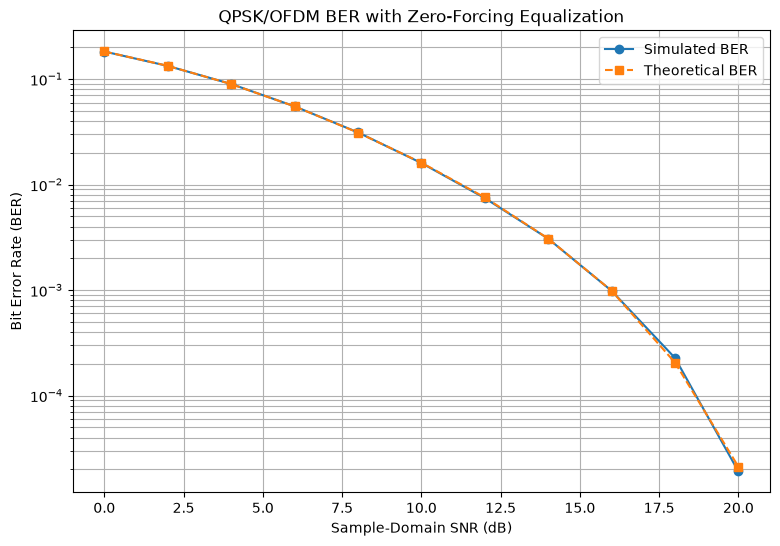

In [11]:
plt.figure(figsize=(9, 6))

plt.semilogy(
    snr_db_values,
    simulated_ber,
    marker="o",
    label="Simulated BER"
)

plt.semilogy(
    snr_db_values,
    theoretical_ber,
    marker="s",
    linestyle="--",
    label="Theoretical BER"
)

plt.xlabel("Sample-Domain SNR (dB)")
plt.ylabel("Bit Error Rate (BER)")
plt.title("QPSK/OFDM BER with Zero-Forcing Equalization")
plt.grid(True, which="both")
plt.legend()

plt.savefig(
    "../results/awgn_ber_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

## Results and Interpretation

The simulation demonstrates the BER performance of the QPSK/OFDM system when additive white Gaussian noise is introduced after the frequency-selective multipath channel and zero-forcing frequency-domain equalization is applied at the receiver.

The BER decreased consistently as the sample-domain SNR increased. At 0 dB, the simulated BER was approximately

$$
1.83 \times 10^{-1},
$$

while at 10 dB it had decreased to approximately

$$
1.60 \times 10^{-2}.
$$

At 20 dB, only 25 bit errors were observed across 1,310,720 transmitted bits, corresponding to a simulated BER of approximately

$$
1.91 \times 10^{-5}.
$$

The Monte Carlo results closely followed the theoretical BER calculated from the channel response. For each subcarrier, zero-forcing equalization divides the received signal by the complex channel coefficient $H[k]$. This removes the deterministic amplitude and phase distortion introduced by the multipath channel, but it also scales the additive noise by $1/H[k]$.

Consequently, subcarriers experiencing small channel magnitudes suffer greater post-equalization noise enhancement. The overall BER is therefore determined by the collection of individual subcarrier gains rather than by a single flat-channel gain.

The close agreement between the simulated and theoretical curves validates the implementation of the complex AWGN model, OFDM receiver, zero-forcing equalizer, QPSK demodulator, and BER calculation. Small differences at the highest SNR values are expected because relatively few bit errors occur there, increasing the statistical variation of the Monte Carlo estimate.

This notebook establishes the noisy frequency-selective-channel baseline for the project. The next notebook extends this noisy-channel baseline by comparing zero-forcing with MMSE equalization. Imperfect channel estimation and more realistic wireless-channel models remain possible directions for future work.

In [12]:
# Final BER-curve validation

bits_per_snr = len(bits) * num_trials

assert np.all(np.diff(simulated_ber) < 0)
assert np.all(simulated_ber > 0)
assert np.all(theoretical_ber > 0)

log_ber_rmse = np.sqrt(
    np.mean(
        (
            np.log10(simulated_ber)
            - np.log10(theoretical_ber)
        ) ** 2
    )
)

print("Bits simulated per SNR point:", bits_per_snr)
print(
    "BER decreases monotonically with SNR:",
    np.all(np.diff(simulated_ber) < 0)
)
print(
    "Log10 BER RMSE between simulation and theory:",
    f"{log_ber_rmse:.4f}"
)

Bits simulated per SNR point: 1310720
BER decreases monotonically with SNR: True
Log10 BER RMSE between simulation and theory: 0.0191
